In [1]:
import os
os.chdir("~/code_epi2hit/")
from Epi2Hit import *

%config InlineBackend.figure_format = 'png'
plt.rcParams['pdf.fonttype'] = 'truetype'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['figure.dpi'] = 100

sns.set_style('white')

# Read initial 450k methylation data after QC

The dataset indexes CpG sites by unique probe IDs (e.g., "cg13869341") and provides columns detailing each site’s genomic location (chromosome, start, end), strand orientation, and methylation measurements. 

Methylation values are available in various contexts, including stromal, immune, and specific prostate cancer cell lines or patient samples. Each CpG site also has a region_ID, a unique identifier combining chromosome and location data (e.g., "chr1_15865_15866").

In [4]:
me_full = read_dataset('~/all_betas_with_confounder_correlation.tsv.gz', 
                       sep=' '
                      )
me_full.shape

(432609, 1685)

 # Select only CpGs that are in a region of open chromatin
 
 To identify CpGs located within regions of open chromatin, I used the Corces PRAD Peaks file for the hg19 genome, Corces_PRAD_Peaks_hg19_hglft_genome_7dc9_e56a20.bed from GSE188797. 
 
 This file provides defined peak regions of accessible chromatin in prostate cancer cells.
 

In [11]:
atac = read_dataset('data/Corces_PRAD_Peaks_hg19_hglft_genome_7dc9_e56a20.bed',
                   index_col=False)[['chrom', 'start', 'end']]
atac.head()

,chrom,start,end
0,chr1,237511,238012
1,chr1,713906,714407
2,chr1,714934,715435
3,chr1,750748,751249
4,chr1,755224,755725


In [ ]:
me = find_open_chromatin_probes(me_full, atac)

In [13]:
me.shape

(119654, 1686)

# Annotate each CpG site with the closest gene

The probes2genes function annotates each CpG methylation probe with the nearest gene(s) based on genomic proximity. Using the specified genome reference (hg19 or hg38), it identifies the closest gene(s) to each probe and calculates the distance. The function returns a DataFrame with probes annotated by their nearest gene(s) and the distance to these genes, indexed by a unique gene-probe identifier. 

example: APC_cg23938220

In [7]:
import pybedtools

In [8]:
pybedtools.__version__

'0.10.0'

In [9]:
gene_ref_paths = {'hg38': '~/38gencode.33.hugo.bed',
                  'hg19': '~/gencode.v19.protein_coding_gene.minimal_chr.bed.gz'}

me_gb = probes2genes(me)

In [16]:
me_gb.shape

(121915, 1689)

# Filtering steps specific criteria and sample types

The dataset was filtered to prioritize CpG sites with tumor-specific methylation patterns:

Immune and Stromal Correlation: Sites with low correlation to immune and stromal cell abundances were retained, highlighting tumor-specific methylation changes.

Global Methylation Loss: Sites were further filtered by the EpiCMIT-hypo score to identify those associated with cumulative mitotic events and partially methylated domains.

Only preselected samples were included, and samples failing QC were removed for refined downstream analysis.

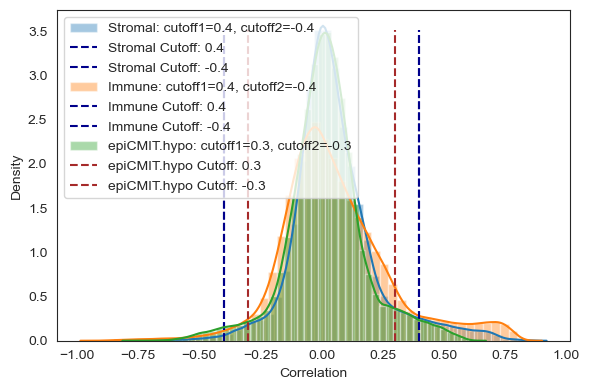

In [11]:
#plot filters before applying
plot_filters(me_gb)

In [26]:
#apply filters
me_filtered = prelim_filters(me_gb)
me_filtered.shape

(105183, 1689)

In [27]:
# preselect samples that passed QC
me_filtered1 = remove_black_listed_samples(me_filtered)
me_filtered1.shape

1348 samples left after filtering with white list + 12 additional columns


(105183, 1360)

In [28]:
# preselect specific types of samples: ['TUM', 'MET']
me_filtered2 = select_type_of_samples(me_filtered1)
me_filtered2.shape

1268 selected


(105183, 1280)

# ChromHMM Annotation for Regulatory Elements

Filtered CpG sites were annotated with chromatin states from prostate-specific ChromHMM data (Pomerantz et al.). We intersected CpG sites with ChromHMM annotations, categorizing them based on chromatin state (e.g., Active Prostate Lineage-Specific Promoter). 

In [39]:
me_with_states = pomerantz_state(me_filtered2, 
                                 reference_bed_path='data/Pomerantz_combined_10_states_colour_final_mod_FOROVERLAP.bed')
me_with_states.shape

(105183, 1282)

In [40]:
me_with_states[['pomerantz', 'pom_region']].head()

,pomerantz,pom_region
un_id,,
AL669831.1_cg01014490,Act_PSP,chr1:713800-714600
AL669831.1_cg23803172,Act_PSP,chr1:762400-763200
AL645608.2_cg03128332,Bival_P,chr1:805000-805800
AL645608.2_cg16619049,Bival_P,chr1:805000-805800
AL645608.1_cg13371836,Bival_P,chr1:839200-841400


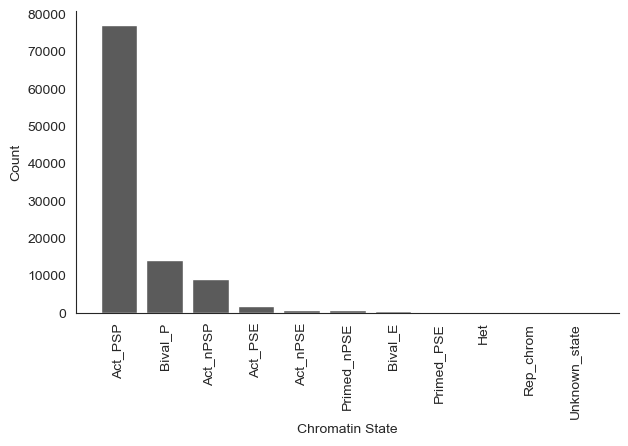

In [37]:
data_counts = me_with_states['pomerantz'].value_counts()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(data_counts.index, data_counts.values, color='#5B5B5B')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xticklabels(data_counts.index, rotation=90)
ax.set_xlabel('Chromatin State')
ax.set_ylabel('Count')
plt.show()

# Merging CpG Sites by Methylation Correlation

CpG sites within the same regulatory region were merged if their methylation levels exhibited a Pearson correlation coefficient greater than 0.6. For each set of correlated sites, the average methylation value was calculated, and the sites were represented as a single entity spanning the combined genomic coordinates of the individual CpG sites.

In [ ]:
final_combined_df = process_probes(me_with_states, 
                                   correlation_threshold=0.6, 
                                   num_cores=16)

# finction resolve cases when for 1 gene we can observe several similar chromatin states (example below)
final_combined_df = resolve_duplicates(final_combined_df)

In [42]:
final_combined_df.shape

(98068, 1283)

In [73]:
# example
final_combined_df[final_combined_df.gene_name=='RNF223'][['pomerantz']]

,pomerantz
RNF223_cg02482614_Bival_P,Bival_P
RNF223_cg16095440_Act_PSP,Act_PSP
RNF223_cg26702212_Bival_P,Bival_P
RNF223_Bival_P,Bival_P
RNF223_Bival_P1,Bival_P


example of CpG sites within the same regulatory region

In [58]:
final_combined_df.loc['APC_Act_nPSP'].id

"['cg23938220', 'cg02511809', 'cg24332422', 'cg15020645']"

In [68]:
me_with_states[me_with_states.id.isin(
    ['cg23938220', 'cg02511809', 'cg24332422', 'cg15020645']
)].iloc[:, 12:-2].T.corr()

un_id,APC_cg23938220,APC_cg02511809,APC_cg24332422,APC_cg15020645
un_id,,,,
APC_cg23938220,1.000000,0.986559,0.941713,0.940620
APC_cg02511809,0.986559,1.000000,0.946546,0.937926
APC_cg24332422,0.941713,0.946546,1.000000,0.978187
APC_cg15020645,0.940620,0.937926,0.978187,1.000000


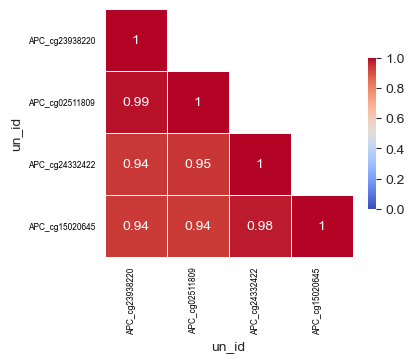

In [71]:
corr_matrix = me_with_states[me_with_states.id.isin(
                            ['cg23938220', 'cg02511809', 'cg24332422', 'cg15020645']
                            )].iloc[:, 12:-2].T.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
plt.figure(figsize=(4, 4))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', 
            linewidths=.5, cbar_kws={"shrink": .5}, square=True,
            vmin=0, vmax=1)
plt.xticks(rotation=90, ha='right', fontsize=6, fontname='Arial', color='black')
plt.yticks(fontsize=6, fontname='Arial', color='black')
plt.show()

# Hi-C Data Integration for Chromatin Loops

Hi-C data from prostate cancer (GEO; GSE164347) was utilized to annotate regulatory CpG sites with chromatin loop information. CpG sites that overlapped loop anchor regions were identified, and corresponding loop IDs were assigned to these sites. To distinguish these CpG sites, a ‘Ls_’ prefix was added to their identifiers. A single CpG site could be associated with multiple chromatin loops, and conversely, a single chromatin loop could encompass multiple CpG sites.

In [72]:
loops = read_dataset('data/loops.bedpe', index_col=False)
loops.head()

,chrom1,start1,end1,chrom2,start2,end2,loop_id,id1,id2,score,pval,midpoint1,midpoint2,N_samples,samples
0,chr1,945380,965380,chr1,1225380,1235380,1_3,1.0,3.0,2.111213,0.112770,955380.0,1230380.0,3.0,"GSM5007983_CPCG0324,GSM5007988_CPCG0331,GSM500..."
1,chr1,1055380,1065380,chr1,1225380,1235380,2_3,2.0,3.0,2.111213,0.091409,1060380.0,1230380.0,3.0,"GSM5007983_CPCG0324,GSM5007988_CPCG0331,GSM500..."
2,chr1,1711439,1721439,chr1,1821439,1831439,4_5,4.0,5.0,2.599208,0.075669,1716439.0,1826439.0,1.0,GSM5007984_CPCG0246
3,chr1,1871439,1881439,chr1,1961439,1981439,6_7,6.0,7.0,2.111213,0.111984,1876439.0,1971439.0,4.0,"GSM5007980_CPCG0366,GSM5007988_CPCG0331,GSM500..."
4,chr1,2121439,2151439,chr1,2241439,2251439,8_9,8.0,9.0,2.111213,0.168864,2136439.0,2246439.0,15.0,"GSM5007979_CPCG0268,GSM5007980_CPCG0366,GSM500..."


In [76]:
final_combined_df_loops = annotate_probes_with_loops(final_combined_df1, loops)

In [100]:
cg16563255 = final_combined_df_loops.loc[['Ls_ZFHX3_cg16563255_Act_nPSP']][['chrom', 'start', 'end']]
cg16563255

,chrom,start,end
Ls_ZFHX3_cg16563255_Act_nPSP,chr16,72995177,72995178


plot ZFHX3 loops 

In [86]:
# sliced bigwigs for visualisation

bigwig_files = [
    "~/H3K27ac_GSE105424_ENCFF994HZA_signal_p-value_hg19.bigWig", #full file
    "~/H3K4me3_GSE96019_ENCFF710JYO_signal_p-value_hg19.bigWig", #full file
    "~/CTCF_GSE123210_ENCFF785IOE_signal_p-value_hg19.bigWig" #full file
]

chromosomes_of_interest = ["chr16"]

for bigwig_path in bigwig_files:
    directory, filename = os.path.split(bigwig_path)
    output_path = os.path.join(directory, filename.replace('.bigWig', '_sliced.bigWig'))
    
    slice_bigwig(bigwig_path, output_path, chromosomes_of_interest)
    print(f"Sliced file saved as {output_path}")

Sliced file saved as /home/dkiriy/data/refs/H3K27ac_GSE105424_ENCFF994HZA_signal_p-value_hg19_sliced.bigWig
Sliced file saved as /home/dkiriy/data/refs/H3K4me3_GSE96019_ENCFF710JYO_signal_p-value_hg19_sliced.bigWig
Sliced file saved as /home/dkiriy/data/refs/CTCF_GSE123210_ENCFF785IOE_signal_p-value_hg19_sliced.bigWig


In [98]:
# genes annotation hg19 for chr16
gff_df = read_dataset('data/GCF_000001405.25_GRCh37.p13_genomic_chr16.gff')
gff_df.head()

,chrom,start,end,gene,type,strand,transcript_id
1734296,chr16,1,90354753,NaN,region,+,NaN
1734297,chr16,61555,64090,DDX11L10,pseudogene,+,NaN
1734298,chr16,61555,64090,DDX11L10,transcript,+,NR_045117.1
1734299,chr16,61555,61908,DDX11L10,exon,+,NR_045117.1
1734300,chr16,62294,62402,DDX11L10,exon,+,NR_045117.1


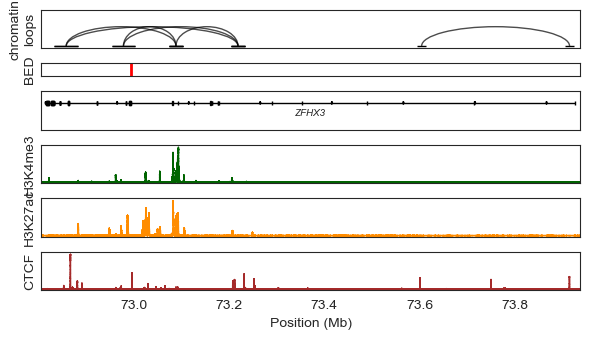

In [114]:
# paths to sliced bigwigs
bigwig_files = [
    "data/H3K4me3_GSE96019_ENCFF710JYO_signal_p-value_hg19_sliced.bigWig",
    "data/H3K27ac_GSE105424_ENCFF994HZA_signal_p-value_hg19_sliced.bigWig",
    "data/CTCF_GSE123210_ENCFF785IOE_signal_p-value_hg19_sliced.bigWig"
]

plot_genes_with_loops_bigwig(gene_data=gff_df, loop_data=loops, 
                             gene1_name='ZFHX3', gene2_name=None, 
                             bigwig_files=bigwig_files, bed_data=cg16563255)


# Methylation and Expression data integration and Linear regression

We first mapped RNA-seq expression sample names to the corresponding methylation sample names using RNA-seq annotation data.

Next, a dictionary was prepared for linear regression, containing gene expression and methylation data for each CpG site. Both methylation and expression data were paired for each gene-CpG combination.

linear regression performed between methylation and expression levels. For each CpG-gene pair, we fitted model, extracting regression coefficients, p-values, confidence intervals, and R-squared values. P-values were adjusted for multiple testing using the FDR method.

In [ ]:
# read expression data
exp_meth = read_exp_data()

In [ ]:
# gene expression and methylation dictionary
gene_ann_me = prepare_dict_for_linreg(exp_meth,
                                      final_combined_df_loops)

In [133]:
gene_ann_me['KLF5_cg14281591_Act_nPSP'].head().style.hide_index()

methylation,expression
0.577447,10.867662
0.684316,9.720874
0.906367,8.321843
0.911058,9.678339
0.486792,9.629375


In [ ]:
# run linear regression
full_genes_meth = lin_reg(gene_ann_me)

 46%|██████████████████████████████████████████████████████████████████████████████▌                                                                                          | 41010/88274 [08:20<11:56, 66.00it/s]

In [134]:
full_genes_meth.loc[['KLF5_cg14281591_Act_nPSP']]

,coef,p_value,q95l,q95h,rsquared,eCpGs,adjusted_p_value,gene
KLF5_cg14281591_Act_nPSP,-1.463573,0.041257,-2.868735,-0.058411,0.012412,KLF5_cg14281591_Act_nPSP,0.057246,KLF5


preselected only sites with negative correlation of methylation and expression

In [142]:
full_genes_meth_filtered.head()

,coef,p_value,q95l,q95h,rsquared,eCpGs,adjusted_p_value,gene
Ls_SLC19A1_cg22240348_Act_PSP,-6.226293,7.350918e-15,-7.729132,-4.723454,0.165455,Ls_SLC19A1_cg22240348_Act_PSP,6.917771e-13,SLC19A1
Ls_KRT18_cg02303897_Bival_P,-3.847534,2.482332e-05,-5.617407,-2.077662,0.051760,Ls_KRT18_cg02303897_Bival_P,7.027847e-05,KRT18
COL6A2_cg05200811_Bival_P,-3.741891,2.144792e-07,-5.131652,-2.352131,0.077264,COL6A2_cg05200811_Bival_P,1.250005e-06,COL6A2
HSPA1B_cg16291635_Act_nPSP,-3.665187,1.339484e-09,-4.820853,-2.509521,0.104649,HSPA1B_cg16291635_Act_nPSP,2.184634e-08,HSPA1B
RPLP1_cg02628483_Act_nPSP,-3.655861,2.494238e-06,-5.156788,-2.154935,0.064131,RPLP1_cg02628483_Act_nPSP,9.648249e-06,RPLP1


In [143]:
len(full_genes_meth_filtered.index)

3150

In [144]:
full_genes_meth_filtered[full_genes_meth_filtered.index.isin([drivers]

,coef,p_value,q95l,q95h,rsquared,eCpGs,adjusted_p_value,gene
PDE4D_Bival_P1,-2.926095,2.709635e-13,-3.681917,-2.170274,0.147568,PDE4D_Bival_P1,1.601440e-11,PDE4D
Ls_PSD3_cg24804106_Bival_P,-2.388269,1.935437e-04,-3.634680,-1.141858,0.040682,Ls_PSD3_cg24804106_Bival_P,4.358156e-04,PSD3
CLDN1_cg03601836_Act_PSE,-2.125687,6.846222e-04,-3.345570,-0.905805,0.033883,CLDN1_cg03601836_Act_PSE,1.359607e-03,CLDN1
Ls_KLF6_cg08614871_Act_PSP,-2.102712,1.547856e-04,-3.183519,-1.021906,0.041887,Ls_KLF6_cg08614871_Act_PSP,3.572639e-04,KLF6
NOTCH1_cg14085952_Bival_E,-1.672542,3.125359e-03,-2.777781,-0.567303,0.025769,NOTCH1_cg14085952_Bival_E,5.405290e-03,NOTCH1
TWIST2_Primed_nPSE,-1.654384,1.580658e-06,-2.320118,-0.988651,0.066580,TWIST2_Primed_nPSE,6.552416e-06,TWIST2
Ls_PTEN_cg07754940_Act_nPSE,-1.648732,5.956051e-03,-2.820453,-0.477012,0.022358,Ls_PTEN_cg07754940_Act_nPSE,9.743291e-03,PTEN
Ls_ZFHX3_cg16563255_Act_nPSP,-1.576988,2.575267e-02,-2.961890,-0.192086,0.014756,Ls_ZFHX3_cg16563255_Act_nPSP,3.724731e-02,ZFHX3
KLF5_cg14281591_Act_nPSP,-1.463573,4.125675e-02,-2.868735,-0.058411,0.012412,KLF5_cg14281591_Act_nPSP,5.724635e-02,KLF5
CDKN1A_cg03032677_Act_nPSP,-1.374732,8.261602e-03,-2.392496,-0.356968,0.020639,CDKN1A_cg03032677_Act_nPSP,1.314809e-02,CDKN1A


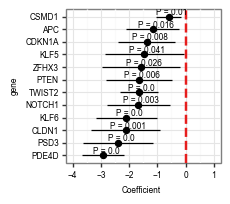

In [152]:
forest_plot(full_genes_meth_filtered[full_genes_meth_filtered.index.isin(drivers)],
                   title='',
                   ylimits=(-4, 1),
                   figsize=(2,2),
                  )


# Categorization of Methylation Levels

Methylation levels for each feature were categorized into three groups: **'Not/Low_methyl'**, **'Medium_methyl'**, and **'Highly_methyl'**, based on predefined thresholds (down_threshold = 0.2, up_threshold = 0.7) and the distribution of methylation values.

- **'Not/Low_methyl'**: Features where all methylation values are below the down_threshold.
- **'Highly_methyl'**: Features where all methylation values are above the up_threshold.
- **'Medium_methyl'**: For features with values spanning these thresholds, we applied kernel density estimation (KDE) using `scipy.stats.gaussian_kde` to estimate the probability density function (PDF). Peaks in the KDE were identified using `scipy.signal.find_peaks` with a prominence threshold set at 3% of the standard deviation of the PDF.

Depending on the number of peaks detected:
- **Single Peak**: A Gaussian Mixture Model (GMM) with three components was fitted using `sklearn.mixture.GaussianMixture`. Methylation categories were assigned based on the cluster means.
- **Two Peaks**: Features with bimodal distributions were manually reviewed, using the lower and upper peaks to categorize methylation levels.
- **Three Peaks**: For trimodal distributions, the median and minimum of the peak values were used for classification.

## Epi2Hit Identification

To identify genes with **biallelic inactivation**, we expanded our previously published methodology to incorporate DNA methylation data. The **Loss/Methylation** category (somatic loss combined with high methylation) was identified as an indicator of biallelic inactivation.


### peaks statistic

In [6]:
beta_values = final_combined_df_loops[final_combined_df_loops.index.isin(
    full_genes_meth_filtered.index)].iloc[:, 12:-4]

<AxesSubplot: xlabel='PRR5_cg19033444_Bival_P', ylabel='Density'>

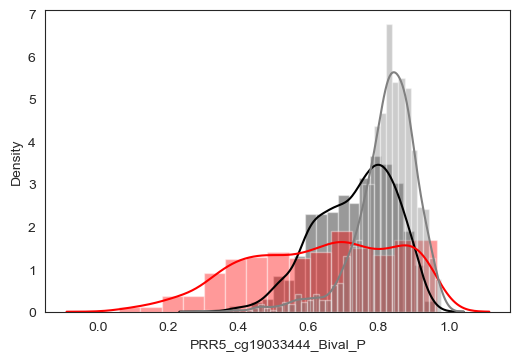

In [191]:
sns.distplot(beta_values.loc['Ls_ZFHX3_cg16563255_Act_nPSP'], kde=True, color='black') # bimodal distribution
sns.distplot(beta_values.loc['KLF5_cg14281591_Act_nPSP'], kde=True, color='r') # trimodal distribution
sns.distplot(beta_values.loc['PRR5_cg19033444_Bival_P'], kde=True, color='grey') # unimodal distribution

In [7]:
cols = ['id',
 'score',
 'strand',
 'gene_name',
 'gene_distance',
 'Stromal',
 'Immune',
 'epiCMIT.hyper',
 'epiCMIT.hypo',
 'pomerantz',
 'pom_region',
 'regions2',
 'loops']

In [9]:
# dataframe with index - methylation site 
#                columns - chrom, start, end, samples
beta_values1 = final_combined_df_loops[final_combined_df_loops.index.isin(
                full_genes_meth_filtered.index)].loc[:,
                ~final_combined_df_loops[final_combined_df_loops.index.isin(
                full_genes_meth_filtered.index)].columns.isin(cols)
]

In [ ]:
labled_methyl = methylation(beta_values1)

In [12]:
labled_methyl.head()

,chrom,start,end,PPCG0001c_450k,PPCG0002c_450k,PPCG0003c_450k,PPCG0004c_450k,PPCG0005c_450k,PPCG0006c_450k,PPCG0007c_450k,...,PPCG1963a_450k,PPCG1964a_450k,PPCG1965a_450k,PPCG1966a_450k,PPCG1967a_450k,PPCG1968a_450k,PPCG1969a_450k,PPCG1970a_450k,PPCG1971a_450k,PPCG1972a_450k
AGRN_cg01244934_Bival_P,chr1,1003417,1003418,Medium_methyl,Medium_methyl,Highly_methyl,Not/Low_methyl,Not/Low_methyl,Not/Low_methyl,Medium_methyl,...,Highly_methyl,Medium_methyl,Highly_methyl,Not/Low_methyl,Not/Low_methyl,Medium_methyl,Medium_methyl,Medium_methyl,Medium_methyl,Medium_methyl
PEX14_cg00003513_Act_PSP,chr1,10757436,10757437,Highly_methyl,Highly_methyl,Highly_methyl,Highly_methyl,Highly_methyl,Highly_methyl,Highly_methyl,...,Highly_methyl,Highly_methyl,Highly_methyl,Highly_methyl,Highly_methyl,Highly_methyl,Highly_methyl,Highly_methyl,Highly_methyl,Highly_methyl
Ls_NKAIN1_cg25010788_Bival_P,chr1,31654453,31654454,Medium_methyl,Not/Low_methyl,Not/Low_methyl,Highly_methyl,Highly_methyl,Medium_methyl,Highly_methyl,...,Highly_methyl,Highly_methyl,Highly_methyl,Medium_methyl,Highly_methyl,Medium_methyl,Medium_methyl,Highly_methyl,Medium_methyl,Medium_methyl
Ls_MEAF6_cg13423759_Act_nPSP,chr1,37937403,37937404,Medium_methyl,Highly_methyl,Highly_methyl,Medium_methyl,Highly_methyl,Highly_methyl,Highly_methyl,...,Highly_methyl,Medium_methyl,Highly_methyl,Medium_methyl,Highly_methyl,Highly_methyl,Medium_methyl,Highly_methyl,Medium_methyl,Highly_methyl
AK4_cg14792081_Bival_P,chr1,65468460,65468461,Medium_methyl,Highly_methyl,Highly_methyl,Medium_methyl,Highly_methyl,Highly_methyl,Highly_methyl,...,Highly_methyl,Highly_methyl,Highly_methyl,Not/Low_methyl,Highly_methyl,Not/Low_methyl,Medium_methyl,Highly_methyl,Medium_methyl,Medium_methyl


In [13]:
labled_methyl.shape

(305, 1271)

# Probe filtering based on methylation categories

In this step, we filter probes based on the distribution of methylation levels across samples. Specifically, we remove probes where more than 70% of the samples fall into either the "Highly_methyl" or "Medium_methyl" categories. 
This ensures we focus on probes with more diverse methylation patterns across samples.

In [214]:
labled_methyl.iloc[:, 3:].apply(lambda x: x.value_counts(), axis=1).head()

,Highly_methyl,Medium_methyl,Not/Low_methyl
AGRN_cg01244934_Bival_P,315.0,640.0,313.0
PEX14_cg00003513_Act_PSP,926.0,305.0,37.0
Ls_NKAIN1_cg25010788_Bival_P,368.0,666.0,234.0
Ls_MEAF6_cg13423759_Act_nPSP,740.0,381.0,147.0
AK4_cg14792081_Bival_P,445.0,670.0,153.0


In [22]:
labled_methyl_filtered = filter_probes_by_methylation(labled_methyl)
labled_methyl_filtered.head()

,chrom,start,end,PPCG0001c_450k,PPCG0002c_450k,PPCG0003c_450k,PPCG0004c_450k,PPCG0005c_450k,PPCG0006c_450k,PPCG0007c_450k,...,PPCG1963a_450k,PPCG1964a_450k,PPCG1965a_450k,PPCG1966a_450k,PPCG1967a_450k,PPCG1968a_450k,PPCG1969a_450k,PPCG1970a_450k,PPCG1971a_450k,PPCG1972a_450k
AGRN_cg01244934_Bival_P,chr1,1003417,1003418,Medium_methyl,Medium_methyl,Highly_methyl,Not/Low_methyl,Not/Low_methyl,Not/Low_methyl,Medium_methyl,...,Highly_methyl,Medium_methyl,Highly_methyl,Not/Low_methyl,Not/Low_methyl,Medium_methyl,Medium_methyl,Medium_methyl,Medium_methyl,Medium_methyl
Ls_NKAIN1_cg25010788_Bival_P,chr1,31654453,31654454,Medium_methyl,Not/Low_methyl,Not/Low_methyl,Highly_methyl,Highly_methyl,Medium_methyl,Highly_methyl,...,Highly_methyl,Highly_methyl,Highly_methyl,Medium_methyl,Highly_methyl,Medium_methyl,Medium_methyl,Highly_methyl,Medium_methyl,Medium_methyl
Ls_MEAF6_cg13423759_Act_nPSP,chr1,37937403,37937404,Medium_methyl,Highly_methyl,Highly_methyl,Medium_methyl,Highly_methyl,Highly_methyl,Highly_methyl,...,Highly_methyl,Medium_methyl,Highly_methyl,Medium_methyl,Highly_methyl,Highly_methyl,Medium_methyl,Highly_methyl,Medium_methyl,Highly_methyl
AK4_cg14792081_Bival_P,chr1,65468460,65468461,Medium_methyl,Highly_methyl,Highly_methyl,Medium_methyl,Highly_methyl,Highly_methyl,Highly_methyl,...,Highly_methyl,Highly_methyl,Highly_methyl,Not/Low_methyl,Highly_methyl,Not/Low_methyl,Medium_methyl,Highly_methyl,Medium_methyl,Medium_methyl
Ls_NOS1AP_cg05381183_Act_nPSE,chr1,162025719,162025720,Not/Low_methyl,Not/Low_methyl,Not/Low_methyl,Not/Low_methyl,Not/Low_methyl,Not/Low_methyl,Not/Low_methyl,...,Medium_methyl,Medium_methyl,Not/Low_methyl,Medium_methyl,Not/Low_methyl,Medium_methyl,Medium_methyl,Not/Low_methyl,Medium_methyl,Medium_methyl


# Running previously published pipeline to identify cases with loss of one allele and methylation of another one

In [25]:
results = read_dataset('~/Biallelic/result_discovery_annotated_methylation.tsv', 
                       index_col=False)
results.head()

,gene,cytoband,first_hit,first_hit_type,second_hit,second_hit_type,hit_type,sample_id,donor_id,id
0,FOXP1,.,chr3:70879240-84806803,HET_LOSS,chr3:71057616-71057617,Highly_methyl,som_loss/methyl,PPCG0001a_DNA,PPCG0001,Ls_FOXP1_Act_PSE
1,FOXP1,.,chr3:70879240-84806803,HET_LOSS,chr3:71106252-71106253,Highly_methyl,som_loss/methyl,PPCG0001a_DNA,PPCG0001,Ls_FOXP1_Act_PSE1
2,CNTN3,.,chr3:70879240-84806803,HET_LOSS,chr3:74512963-74512964,Highly_methyl,som_loss/methyl,PPCG0001a_DNA,PPCG0001,CNTN3_cg11635155_Primed_PSE
3,ZNF516,.,chr18:70214053-77985696,HET_LOSS,chr18:74172098-74172099,Highly_methyl,som_loss/methyl,PPCG0002a_DNA,PPCG0002,7169_ZNF516_cg15347788_Act_nPSP
4,SRGAP3,.,chr3:8337950-9375530,HET_LOSS,chr3:9258433-9258574,Highly_methyl,som_loss/methyl,PPCG0002a_DNA,PPCG0002,SRGAP3_Act_nPSE


In [26]:
results.shape

(10530, 10)